In [7]:
import os
import json
import shutil
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from pathlib import Path
from nibabel.processing import resample_to_output

print("Libraries imported successfully.")

Libraries imported successfully.


In [8]:
from pathlib import Path
import os

print("Current working directory:")
print(Path.cwd())

Current working directory:
c:\Users\mmadh\DIP_cap\DIP_Capestone\notebook


In [10]:
from pathlib import Path

# Current notebook directory
CODE_DIR = Path.cwd()

# Project directory
PROJECT_DIR = CODE_DIR.parent

# Your actual dataset location
DATA_DIR = Path(r"C:\Users\mmadh\dataset\processed_member1\processed_member1")

# Output directory inside your project
OUTPUT_DIR = PROJECT_DIR / "processed_member1"

# Create output directory
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Verify paths
print("Current working directory:")
print(CODE_DIR)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nDataset directory:")
print(DATA_DIR)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nDataset exists:", DATA_DIR.exists())

Current working directory:
c:\Users\mmadh\DIP_cap\DIP_Capestone\notebook

Project directory:
c:\Users\mmadh\DIP_cap\DIP_Capestone

Dataset directory:
C:\Users\mmadh\dataset\processed_member1\processed_member1

Output directory:
c:\Users\mmadh\DIP_cap\DIP_Capestone\processed_member1

Dataset exists: True


In [13]:
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\mmadh\dataset\processed_member1\processed_member1"
)

fmri_files = sorted(
    DATA_DIR.glob("sub-*/sub-*_task-fe_bold_processed.nii.gz")
)

print("Total samples:", len(fmri_files))

Total samples: 40


In [14]:
# Verify fMRI dataset properties

dataset_info = []

for file in fmri_files:
    img = nib.load(file)

    zooms = img.header.get_zooms()

    dataset_info.append({
        "subject": file.parent.parent.name,
        "shape": img.shape,
        "voxel_x": zooms[0],
        "voxel_y": zooms[1],
        "voxel_z": zooms[2],
        "TR": zooms[3] if len(zooms) > 3 else np.nan,
        "dtype": img.get_data_dtype(),
    })

dataset_info = pd.DataFrame(dataset_info)

display(dataset_info)

,subject,shape,voxel_x,voxel_y,voxel_z,TR,dtype
0,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
1,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
2,processed_member1,"(128, 128, 36, 200)",1.789827,1.789827,4.0,3.000001,float32
3,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
4,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
5,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
6,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
7,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
8,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
9,processed_member1,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32


In [15]:
import nibabel as nib
import pandas as pd

rows = []

for file in fmri_files:
    img = nib.load(file)

    rows.append({
        "subject": file.parent.name,
        "shape": img.shape,
        "voxel_x": img.header.get_zooms()[0],
        "voxel_y": img.header.get_zooms()[1],
        "voxel_z": img.header.get_zooms()[2],
        "TR": img.header.get_zooms()[3],
        "dtype": img.get_data_dtype()
    })

fmri_info = pd.DataFrame(rows)

fmri_info

,subject,shape,voxel_x,voxel_y,voxel_z,TR,dtype
0,sub-01,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
1,sub-02,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
2,sub-03,"(128, 128, 36, 200)",1.789827,1.789827,4.0,3.000001,float32
3,sub-04,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
4,sub-05,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
5,sub-06,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
6,sub-07,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
7,sub-08,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
8,sub-09,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32
9,sub-10,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,float32


In [16]:
print("Total samples:", len(fmri_info))
print("Unique shapes:")
print(fmri_info["shape"].value_counts())

print("\nData types:")
print(fmri_info["dtype"].value_counts())

print("\nTR values:")
print(fmri_info["TR"].value_counts())

Total samples: 40
Unique shapes:
shape
(128, 128, 36, 200)    40
Name: count, dtype: int64

Data types:
dtype
float32    40
Name: count, dtype: int64

TR values:
TR
3.000001    40
Name: count, dtype: int64


In [17]:
import nibabel as nib
import numpy as np

# Load first subject
file_path = fmri_files[0]

img = nib.load(file_path)
data = img.get_fdata(dtype=np.float32)

print("Subject:", fmri_files[0].parent.name)
print("Shape:", data.shape)
print("Minimum:", np.min(data))
print("Maximum:", np.max(data))
print("Mean:", np.mean(data))
print("Standard deviation:", np.std(data))

Subject: sub-01
Shape: (128, 128, 36, 200)
Minimum: 0.0
Maximum: 1.0
Mean: 0.33852175
Standard deviation: 0.33479184


In [18]:
# Check affine matrices and image orientations

orientation_info = []

for file in fmri_files:
    img = nib.load(file)

    orientation = nib.aff2axcodes(img.affine)

    orientation_info.append({
        "subject": file.parent.parent.name,
        "orientation": "".join(orientation),
        "affine": img.affine
    })

orientation_df = pd.DataFrame(
    [
        {
            "subject": item["subject"],
            "orientation": item["orientation"]
        }
        for item in orientation_info
    ]
)

display(orientation_df)

print("\nUnique orientations:")
print(orientation_df["orientation"].value_counts())

,subject,orientation
0,processed_member1,LAS
1,processed_member1,LAS
2,processed_member1,LAS
3,processed_member1,LAS
4,processed_member1,LAS
5,processed_member1,LAS
6,processed_member1,LAS
7,processed_member1,LAS
8,processed_member1,LAS
9,processed_member1,LAS



Unique orientations:
orientation
LAS    40
Name: count, dtype: int64


In [19]:
# Check intensity characteristics for all subjects

intensity_summary = []

for file in fmri_files:
    img = nib.load(file)
    data = img.get_fdata(dtype=np.float32)

    nonzero = data[data > 0]

    intensity_summary.append({
        "subject": file.parent.parent.name,
        "min": float(data.min()),
        "max": float(data.max()),
        "mean": float(data.mean()),
        "std": float(data.std()),
        "p1": float(np.percentile(nonzero, 1)),
        "p5": float(np.percentile(nonzero, 5)),
        "median": float(np.percentile(nonzero, 50)),
        "p95": float(np.percentile(nonzero, 95)),
        "p99": float(np.percentile(nonzero, 99)),
        "zero_percentage": float(
            100 * np.mean(data == 0)
        )
    })

intensity_summary = pd.DataFrame(intensity_summary)

display(intensity_summary)

KeyboardInterrupt: 

In [25]:
# Fast intensity analysis for preprocessing decision

sample_subjects = ["sub-01", "sub-10", "sub-20", "sub-30", "sub-40"]

sample_files = [
    file
    for file in fmri_files
    if file.parent.parent.name in sample_subjects
]

intensity_summary = []

for file in sample_files:

    subject = file.parent.parent.name
    print("Analyzing:", subject)

    img = nib.load(file)

    # Load only the first time point
    data = img.slicer[:, :, :, 0].get_fdata(dtype=np.float32)

    nonzero = data[data > 0]

    intensity_summary.append({
        "subject": subject,
        "min": float(data.min()),
        "max": float(data.max()),
        "mean": float(data.mean()),
        "std": float(data.std()),
        "p1": float(np.percentile(nonzero, 1)),
        "p5": float(np.percentile(nonzero, 5)),
        "median": float(np.percentile(nonzero, 50)),
        "p95": float(np.percentile(nonzero, 95)),
        "p99": float(np.percentile(nonzero, 99)),
        "zero_percentage": float(
            100 * np.mean(data == 0)
        )
    })

intensity_summary = pd.DataFrame(intensity_summary)

display(intensity_summary)

""


In [24]:
# ============================================
# Log Transformation - Sub-01
# ============================================

# Select sub-01
sub01_file = [
    file for file in fmri_files
    if file.parent.parent.name == "sub-01"
][0]

# Load NIfTI
sub01_img = nib.load(sub01_file)

# Load data as float32
sub01_data = sub01_img.get_fdata(dtype=np.float32)

print("Original shape:", sub01_data.shape)
print("Original dtype:", sub01_data.dtype)

# ------------------------------------------------
# Log transformation
# ------------------------------------------------

# Create output array
log_data = np.zeros_like(sub01_data, dtype=np.float32)

# Preserve background voxels (zero values)
nonzero_mask = sub01_data > 0

# Log transformation
log_data[nonzero_mask] = np.log1p(
    sub01_data[nonzero_mask]
)

print("\nLog transformation completed.")

print("\nOriginal intensity:")
print("Min :", sub01_data.min())
print("Max :", sub01_data.max())
print("Mean:", sub01_data.mean())
print("Std :", sub01_data.std())

print("\nLog-transformed intensity:")
print("Min :", log_data.min())
print("Max :", log_data.max())
print("Mean:", log_data.mean())
print("Std :", log_data.std())

IndexError: list index out of range

In [11]:
# ============================================
# Visual comparison
# ============================================

time_index = 0
z = sub01_data.shape[2] // 2

original_slice = sub01_data[:, :, z, time_index]
log_slice = log_data[:, :, z, time_index]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original
axes[0].imshow(
    original_slice.T,
    cmap="gray",
    origin="lower"
)

axes[0].set_title(
    "Sub-01 - Original"
)

axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")

# Log transformed
axes[1].imshow(
    log_slice.T,
    cmap="gray",
    origin="lower"
)

axes[1].set_title(
    "Sub-01 - Log Transformed"
)

axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")

plt.tight_layout()
plt.show()

NameError: name 'sub01_data' is not defined

In [12]:
# ============================================
# Contrast Stretching - Sub-01
# Applied after Log Transformation
# ============================================

# Create output array
contrast_data = np.zeros_like(
    log_data,
    dtype=np.float32
)

# Non-zero voxels
nonzero_mask = log_data > 0

# Get robust lower and upper intensity limits
lower_percentile = np.percentile(
    log_data[nonzero_mask],
    2
)

upper_percentile = np.percentile(
    log_data[nonzero_mask],
    98
)

print("Lower percentile (2%):", lower_percentile)
print("Upper percentile (98%):", upper_percentile)


# Contrast stretching
contrast_data[nonzero_mask] = np.clip(
    (
        log_data[nonzero_mask] - lower_percentile
    )
    /
    (
        upper_percentile - lower_percentile
    ),
    0,
    1
)


print("\nContrast stretching completed.")

print("\nLog-transformed data:")
print("Min :", log_data.min())
print("Max :", log_data.max())
print("Mean:", log_data.mean())
print("Std :", log_data.std())

print("\nAfter contrast stretching:")
print("Min :", contrast_data.min())
print("Max :", contrast_data.max())
print("Mean:", contrast_data.mean())
print("Std :", contrast_data.std())

Lower percentile (2%): 3.607789993286133
Upper percentile (98%): 10.889534950256348

Contrast stretching completed.

Log-transformed data:
Min : 0.0
Max : 11.79288
Mean: 5.72995
Std : 2.963848

After contrast stretching:
Min : 0.0
Max : 1.0
Mean: 0.33852175
Std : 0.33479184


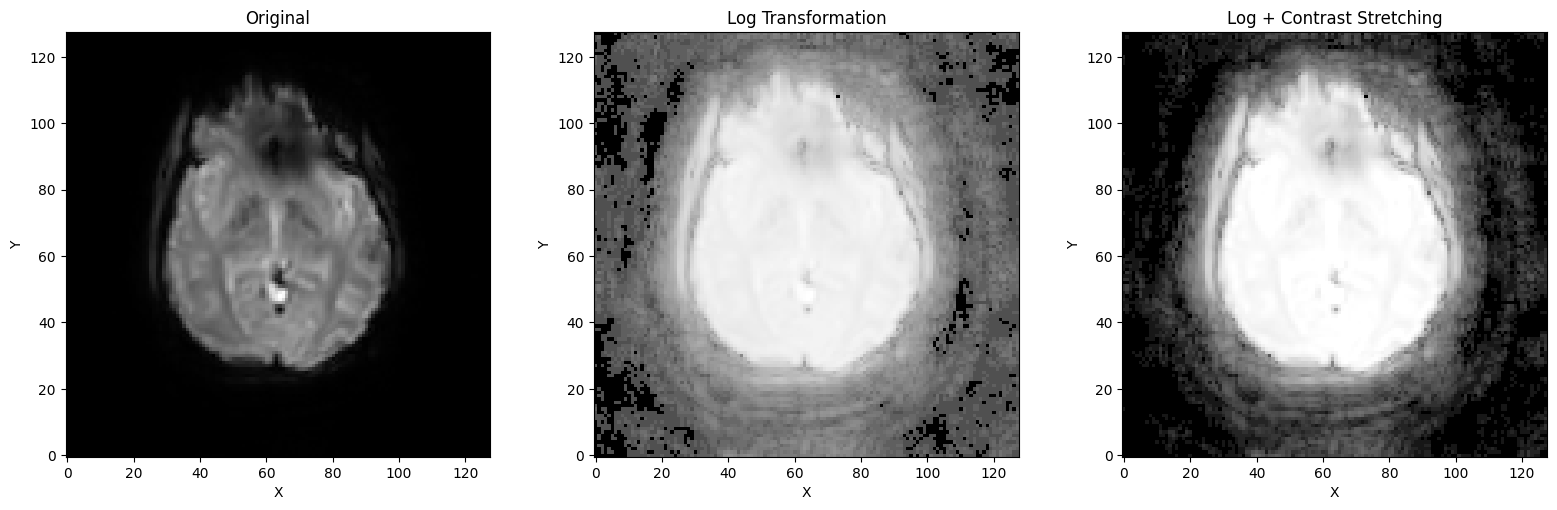

In [13]:
# ============================================
# Original vs Log vs Contrast Stretching
# ============================================

time_index = 0
z = sub01_data.shape[2] // 2

original_slice = sub01_data[:, :, z, time_index]
log_slice = log_data[:, :, z, time_index]
contrast_slice = contrast_data[:, :, z, time_index]


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)


# Original
axes[0].imshow(
    original_slice.T,
    cmap="gray",
    origin="lower"
)

axes[0].set_title("Original")


# Log
axes[1].imshow(
    log_slice.T,
    cmap="gray",
    origin="lower"
)

axes[1].set_title("Log Transformation")


# Contrast stretched
axes[2].imshow(
    contrast_slice.T,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "Log + Contrast Stretching"
)


for ax in axes:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")


plt.tight_layout()
plt.show()

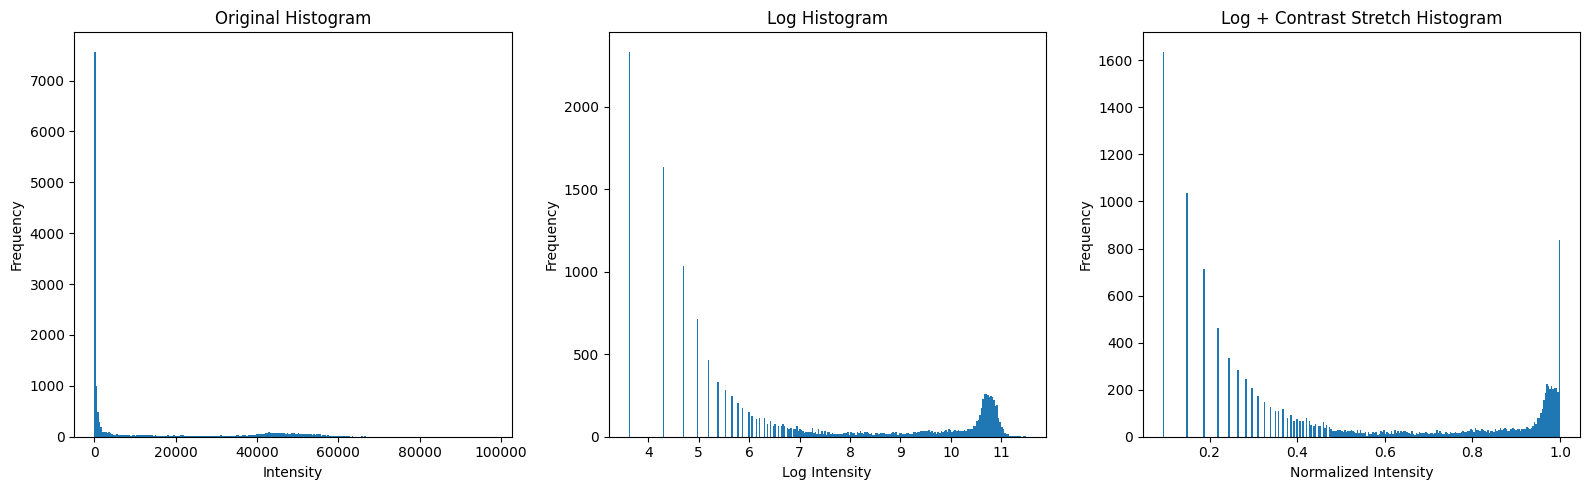

In [14]:
# ============================================
# Histogram comparison
# ============================================

original_nonzero = original_slice[
    original_slice > 0
]

log_nonzero = log_slice[
    log_slice > 0
]

contrast_nonzero = contrast_slice[
    contrast_slice > 0
]


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)


# Original
axes[0].hist(
    original_nonzero,
    bins=256
)

axes[0].set_title(
    "Original Histogram"
)

axes[0].set_xlabel("Intensity")
axes[0].set_ylabel("Frequency")


# Log
axes[1].hist(
    log_nonzero,
    bins=256
)

axes[1].set_title(
    "Log Histogram"
)

axes[1].set_xlabel("Log Intensity")
axes[1].set_ylabel("Frequency")


# Contrast
axes[2].hist(
    contrast_nonzero,
    bins=256
)

axes[2].set_title(
    "Log + Contrast Stretch Histogram"
)

axes[2].set_xlabel("Normalized Intensity")
axes[2].set_ylabel("Frequency")


plt.tight_layout()
plt.show()

In [15]:
# Check the effect of percentile clipping

nonzero_log = log_data[log_data > 0]

lower = np.percentile(nonzero_log, 2)
upper = np.percentile(nonzero_log, 98)

below_lower = np.sum(nonzero_log < lower)
above_upper = np.sum(nonzero_log > upper)
total_nonzero = len(nonzero_log)

print("Lower threshold:", lower)
print("Upper threshold:", upper)

print("\nValues below lower threshold:")
print(below_lower)

print("Values above upper threshold:")
print(above_upper)

print("Total non-zero values:")
print(total_nonzero)

print("\nPercentage clipped at lower end:")
print(100 * below_lower / total_nonzero, "%")

print("Percentage clipped at upper end:")
print(100 * above_upper / total_nonzero, "%")

Lower threshold: 3.607789993286133
Upper threshold: 10.889534950256348

Values below lower threshold:
0
Values above upper threshold:
2127242
Total non-zero values:
106697877

Percentage clipped at lower end:
0.0 %
Percentage clipped at upper end:
1.9937060228480459 %


In [16]:
import gc
import time
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd


# --------------------------------------------------
# PATHS
# --------------------------------------------------

CODE_DIR = Path.cwd()
DATA_DIR = CODE_DIR / "data"
OUTPUT_DIR = CODE_DIR / "processed_member1"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# FIND ALL 40 TASK-FE FILES
# --------------------------------------------------

fmri_files = sorted(
    DATA_DIR.glob("sub-*/func/*_task-fe_bold.nii.gz")
)

print("Total subjects found:", len(fmri_files))

for file in fmri_files:
    print(file)


# --------------------------------------------------
# PROCESS ALL 40 SUBJECTS
# --------------------------------------------------

processing_records = []

total_subjects = len(fmri_files)

for index, input_file in enumerate(fmri_files, start=1):

    subject = input_file.parent.parent.name
    start_time = time.time()

    print("\n" + "=" * 60)
    print(f"Processing {index}/{total_subjects}: {subject}")
    print("=" * 60)

    try:

        # --------------------------------------------------
        # LOAD NIFTI
        # --------------------------------------------------

        img = nib.load(input_file)

        data = img.get_fdata(dtype=np.float32)

        original_shape = data.shape

        print("Original shape:", original_shape)


        # --------------------------------------------------
        # 1. LOG TRANSFORMATION
        # --------------------------------------------------

        nonzero_mask = data > 0

        data[nonzero_mask] = np.log1p(data[nonzero_mask])


        # --------------------------------------------------
        # 2. CONTRAST STRETCHING
        #    Using 2nd and 98th percentiles
        # --------------------------------------------------

        nonzero_values = data[nonzero_mask]

        lower = np.percentile(nonzero_values, 2)
        upper = np.percentile(nonzero_values, 98)

        if upper <= lower:
            raise ValueError(
                f"Invalid percentile range: P2={lower}, P98={upper}"
            )

        data[nonzero_mask] = np.clip(
            (data[nonzero_mask] - lower) /
            (upper - lower),
            0,
            1
        )


        # --------------------------------------------------
        # SAVE PROCESSED DATA
        # --------------------------------------------------

        subject_output_dir = OUTPUT_DIR / subject
        subject_output_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        output_file = (
            subject_output_dir /
            f"{subject}_task-fe_bold_processed.nii.gz"
        )


        # --------------------------------------------------
        # PRESERVE NIFTI INFORMATION
        # --------------------------------------------------

        header = img.header.copy()

        header.set_data_dtype(np.float32)

        # Prevent unwanted intensity scaling
        header.set_slope_inter(1.0, 0.0)

        processed_img = nib.Nifti1Image(
            data,
            img.affine,
            header
        )

        nib.save(
            processed_img,
            output_file
        )


        # --------------------------------------------------
        # RECORD INFORMATION
        # --------------------------------------------------

        elapsed = time.time() - start_time

        processing_records.append({
            "subject": subject,
            "input_file": str(input_file),
            "output_file": str(output_file),
            "shape": str(original_shape),
            "P2": float(lower),
            "P98": float(upper),
            "output_min": float(data.min()),
            "output_max": float(data.max()),
            "output_mean": float(data.mean()),
            "output_std": float(data.std()),
            "status": "success",
            "time_seconds": round(elapsed, 2)
        })


        print("P2:", round(lower, 4))
        print("P98:", round(upper, 4))
        print("Output range: [0, 1]")
        print("Saved:", output_file)
        print(f"Time: {elapsed:.2f} seconds")


        # --------------------------------------------------
        # FREE MEMORY
        # --------------------------------------------------

        del data
        del processed_img
        del img
        del nonzero_mask
        del nonzero_values

        gc.collect()


    except Exception as e:

        processing_records.append({
            "subject": subject,
            "input_file": str(input_file),
            "output_file": "",
            "shape": "",
            "P2": np.nan,
            "P98": np.nan,
            "output_min": np.nan,
            "output_max": np.nan,
            "output_mean": np.nan,
            "output_std": np.nan,
            "status": f"failed: {e}",
            "time_seconds": np.nan
        })

        print("ERROR:", e)

        gc.collect()


# --------------------------------------------------
# CREATE PROCESSING MANIFEST
# --------------------------------------------------

processing_manifest = pd.DataFrame(processing_records)

manifest_file = (
    OUTPUT_DIR /
    "member1_processing_manifest.csv"
)

processing_manifest.to_csv(
    manifest_file,
    index=False
)


# --------------------------------------------------
# FINAL SUMMARY
# --------------------------------------------------

successful = (
    processing_manifest["status"] == "success"
).sum()

failed = (
    processing_manifest["status"] != "success"
).sum()

print("\n" + "=" * 60)
print("PROCESSING COMPLETED")
print("=" * 60)

print("Total subjects:", total_subjects)
print("Successful:", successful)
print("Failed:", failed)

print("\nManifest saved to:")
print(manifest_file)

display(processing_manifest)

Total subjects found: 40
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-01\func\sub-01_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-02\func\sub-02_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-03\func\sub-03_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-04\func\sub-04_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-05\func\sub-05_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-06\func\sub-06_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-07\func\sub-07_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-08\func\sub-08_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-09\func\sub-09_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-10\func\sub-10_task-fe_bold.nii.gz
D:\co

,subject,input_file,output_file,shape,P2,P98,output_min,output_max,output_mean,output_std,status,time_seconds
0,sub-01,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.607790,10.889535,0.0,1.0,0.338522,0.334792,success,52.65
1,sub-02,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.654612,10.963400,0.0,1.0,0.354719,0.350425,success,44.02
2,sub-03,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.765176,10.947392,0.0,1.0,0.323890,0.336272,success,50.05
3,sub-04,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.615118,10.940294,0.0,1.0,0.353372,0.356724,success,47.85
4,sub-05,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.616889,10.898217,0.0,1.0,0.346699,0.351216,success,58.48
5,sub-06,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.761746,10.994543,0.0,1.0,0.338187,0.340792,success,54.24
6,sub-07,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.612557,10.878241,0.0,1.0,0.373425,0.341129,success,55.69
7,sub-08,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.671329,10.956124,0.0,1.0,0.362878,0.346570,success,55.17
8,sub-09,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.652911,10.871614,0.0,1.0,0.317252,0.340405,success,49.41
9,sub-10,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.505656,10.911805,0.0,1.0,0.360792,0.331126,success,56.09


In [17]:
from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd

# --------------------------------------------------
# PATH
# --------------------------------------------------

OUTPUT_DIR = Path.cwd() / "processed_member1"

# --------------------------------------------------
# FIND ALL PROCESSED FILES
# --------------------------------------------------

processed_files = sorted(
    OUTPUT_DIR.glob("sub-*/ *_task-fe_bold_processed.nii.gz".replace(" ", ""))
)

print("Processed files found:", len(processed_files))

# --------------------------------------------------
# VERIFY EACH SUBJECT
# --------------------------------------------------

verification_records = []

for file in processed_files:

    subject = file.parent.name

    img = nib.load(file)
    data = img.get_fdata(dtype=np.float32)

    verification_records.append({
        "subject": subject,
        "shape": data.shape,
        "dtype": str(data.dtype),
        "min": float(np.min(data)),
        "max": float(np.max(data)),
        "mean": float(np.mean(data)),
        "std": float(np.std(data)),
        "NaN": bool(np.isnan(data).any()),
        "Inf": bool(np.isinf(data).any()),
        "voxel_x": float(img.header.get_zooms()[0]),
        "voxel_y": float(img.header.get_zooms()[1]),
        "voxel_z": float(img.header.get_zooms()[2]),
        "TR": float(img.header.get_zooms()[3])
    })

    del data

# --------------------------------------------------
# DISPLAY RESULTS
# --------------------------------------------------

verification_df = pd.DataFrame(verification_records)

display(verification_df)

Processed files found: 40


,subject,shape,dtype,min,max,mean,std,NaN,Inf,voxel_x,voxel_y,voxel_z,TR
0,sub-01,"(128, 128, 36, 200)",float32,0.0,1.0,0.338522,0.334792,False,False,1.796875,1.796875,4.0,3.000001
1,sub-02,"(128, 128, 36, 200)",float32,0.0,1.0,0.354719,0.350425,False,False,1.796875,1.796875,4.0,3.000001
2,sub-03,"(128, 128, 36, 200)",float32,0.0,1.0,0.323890,0.336272,False,False,1.789827,1.789827,4.0,3.000001
3,sub-04,"(128, 128, 36, 200)",float32,0.0,1.0,0.353372,0.356724,False,False,1.796875,1.796875,4.0,3.000001
4,sub-05,"(128, 128, 36, 200)",float32,0.0,1.0,0.346699,0.351216,False,False,1.796875,1.796875,4.0,3.000001
5,sub-06,"(128, 128, 36, 200)",float32,0.0,1.0,0.338187,0.340792,False,False,1.796875,1.796875,4.0,3.000001
6,sub-07,"(128, 128, 36, 200)",float32,0.0,1.0,0.373425,0.341129,False,False,1.796875,1.796875,4.0,3.000001
7,sub-08,"(128, 128, 36, 200)",float32,0.0,1.0,0.362878,0.346570,False,False,1.796875,1.796875,4.0,3.000001
8,sub-09,"(128, 128, 36, 200)",float32,0.0,1.0,0.317252,0.340405,False,False,1.796875,1.796875,4.0,3.000001
9,sub-10,"(128, 128, 36, 200)",float32,0.0,1.0,0.360792,0.331126,False,False,1.796875,1.796875,4.0,3.000001


In [18]:
import nibabel as nib
from pathlib import Path

RAW_DIR = Path.cwd() / "data"
PROCESSED_DIR = Path.cwd() / "processed_member1"

results = []

for subject in sorted(
    [f"sub-{i:02d}" for i in range(1, 41)]
):
    raw_file = RAW_DIR / subject / "func" / f"{subject}_task-fe_bold.nii.gz"
    processed_file = (
        PROCESSED_DIR / subject /
        f"{subject}_task-fe_bold_processed.nii.gz"
    )

    raw_img = nib.load(raw_file)
    processed_img = nib.load(processed_file)

    results.append({
        "subject": subject,
        "raw_orientation": "".join(nib.aff2axcodes(raw_img.affine)),
        "processed_orientation": "".join(nib.aff2axcodes(processed_img.affine)),
        "affine_same": np.allclose(
            raw_img.affine,
            processed_img.affine
        )
    })

orientation_df = pd.DataFrame(results)

display(orientation_df)

print("All orientations preserved:",
      (orientation_df["raw_orientation"] ==
       orientation_df["processed_orientation"]).all())

print("All affines preserved:",
      orientation_df["affine_same"].all())

,subject,raw_orientation,processed_orientation,affine_same
0,sub-01,LAS,LAS,True
1,sub-02,LAS,LAS,True
2,sub-03,LAS,LAS,True
3,sub-04,LAS,LAS,True
4,sub-05,LAS,LAS,True
5,sub-06,LAS,LAS,True
6,sub-07,LAS,LAS,True
7,sub-08,LAS,LAS,True
8,sub-09,LAS,LAS,True
9,sub-10,LAS,LAS,True


All orientations preserved: True
All affines preserved: True


FILTERING

In [34]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.ndimage import gaussian_filter

In [35]:
PROCESSED_DIR = Path(
    r"C:\Users\mmadh\dataset\processed_member1\processed_member1"
)

GAUSSIAN_DIR = PROCESSED_DIR / "gaussian"
GAUSSIAN_DIR.mkdir(parents=True, exist_ok=True)

fmri_files = sorted(
    PROCESSED_DIR.glob(
        "sub-*/sub-*_task-fe_bold_processed.nii.gz"
    )
)

print("Total files:", len(fmri_files))

Total files: 40


Gaussian filter

In [37]:
sigma = 1.0

for file in fmri_files:

    subject = file.parent.name

    print(f"Processing {subject}...")

    img = nib.load(file)
    data = img.get_fdata(dtype=np.float32)

    gaussian_data = np.zeros_like(
        data,
        dtype=np.float32
    )

    # Apply Gaussian filter to every time frame
    for t in range(data.shape[3]):

        gaussian_data[:, :, :, t] = gaussian_filter(
            data[:, :, :, t],
            sigma=sigma
        )

    # Save result
    output_file = (
        GAUSSIAN_DIR /
        f"{subject}_gaussian.nii.gz"
    )

    nib.save(
        nib.Nifti1Image(
            gaussian_data,
            img.affine,
            img.header
        ),
        output_file
    )

    del data
    del gaussian_data

    print(f"{subject} completed.")

Processing sub-01...
sub-01 completed.
Processing sub-02...
sub-02 completed.
Processing sub-03...
sub-03 completed.
Processing sub-04...
sub-04 completed.
Processing sub-05...
sub-05 completed.
Processing sub-06...
sub-06 completed.
Processing sub-07...
sub-07 completed.
Processing sub-08...
sub-08 completed.
Processing sub-09...
sub-09 completed.
Processing sub-10...
sub-10 completed.
Processing sub-11...
sub-11 completed.
Processing sub-12...
sub-12 completed.
Processing sub-13...
sub-13 completed.
Processing sub-14...
sub-14 completed.
Processing sub-15...
sub-15 completed.
Processing sub-16...
sub-16 completed.
Processing sub-17...
sub-17 completed.
Processing sub-18...
sub-18 completed.
Processing sub-19...
sub-19 completed.
Processing sub-20...
sub-20 completed.
Processing sub-21...
sub-21 completed.
Processing sub-22...
sub-22 completed.
Processing sub-23...
sub-23 completed.
Processing sub-24...
sub-24 completed.
Processing sub-25...
sub-25 completed.
Processing sub-26...
sub-

In [38]:
gaussian_files = list(
    GAUSSIAN_DIR.glob("*.nii.gz")
)

print("Gaussian files created:", len(gaussian_files))

Gaussian files created: 40


In [39]:
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

PROCESSED_DIR = Path(
    r"C:\Users\mmadh\dataset\processed_member1\processed_member1"
)

GAUSSIAN_DIR = PROCESSED_DIR / "gaussian"

subject = "sub-01"

original_file = (
    PROCESSED_DIR /
    subject /
    f"{subject}_task-fe_bold_processed.nii.gz"
)

gaussian_file = (
    GAUSSIAN_DIR /
    f"{subject}_gaussian.nii.gz"
)

original = nib.load(original_file).get_fdata()
gaussian = nib.load(gaussian_file).get_fdata()

print("Original shape:", original.shape)
print("Gaussian shape:", gaussian.shape)

Original shape: (128, 128, 36, 200)
Gaussian shape: (128, 128, 36, 200)


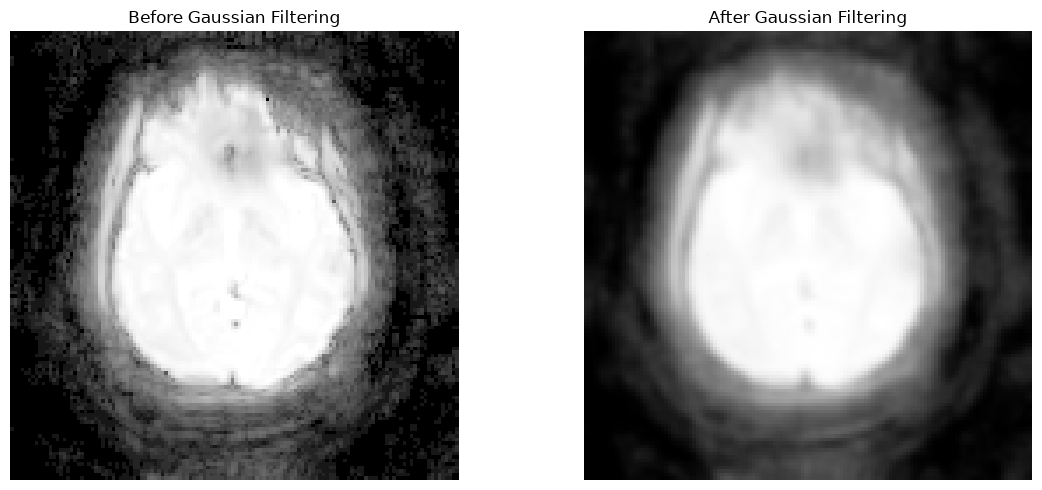

In [40]:
time_index = 0
z = original.shape[2] // 2

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    original[:, :, z, time_index].T,
    cmap="gray",
    origin="lower"
)

plt.title("Before Gaussian Filtering")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    gaussian[:, :, z, time_index].T,
    cmap="gray",
    origin="lower"
)

plt.title("After Gaussian Filtering")
plt.axis("off")

plt.tight_layout()
plt.show()

Fourier Transform

In [41]:
import nibabel as nib
import numpy as np
from pathlib import Path

In [42]:
PROCESSED_DIR = Path(
    r"C:\Users\mmadh\dataset\processed_member1\processed_member1"
)

GAUSSIAN_DIR = PROCESSED_DIR / "gaussian"

FOURIER_DIR = PROCESSED_DIR / "fourier"
FOURIER_DIR.mkdir(parents=True, exist_ok=True)

gaussian_files = sorted(
    GAUSSIAN_DIR.glob("*_gaussian.nii.gz")
)

print("Gaussian files:", len(gaussian_files))

Gaussian files: 40


In [43]:
for file in gaussian_files:

    subject = file.name.split("_gaussian")[0]

    print(f"Processing {subject}...")

    img = nib.load(file)
    data = img.get_fdata(dtype=np.float32)

    fourier_magnitude = np.zeros_like(
        data,
        dtype=np.float32
    )

    # Fourier transform for each time frame
    for t in range(data.shape[3]):

        fft_volume = np.fft.fftn(
            data[:, :, :, t]
        )

        fft_volume = np.fft.fftshift(
            fft_volume
        )

        fourier_magnitude[:, :, :, t] = np.abs(
            fft_volume
        )

    # Save magnitude spectrum
    output_file = (
        FOURIER_DIR /
        f"{subject}_fourier_magnitude.nii.gz"
    )

    nib.save(
        nib.Nifti1Image(
            fourier_magnitude,
            img.affine,
            img.header
        ),
        output_file
    )

    del data
    del fourier_magnitude

    print(f"{subject} completed.")

Processing sub-01...
sub-01 completed.
Processing sub-02...
sub-02 completed.
Processing sub-03...
sub-03 completed.
Processing sub-04...
sub-04 completed.
Processing sub-05...
sub-05 completed.
Processing sub-06...
sub-06 completed.
Processing sub-07...
sub-07 completed.
Processing sub-08...
sub-08 completed.
Processing sub-09...
sub-09 completed.
Processing sub-10...
sub-10 completed.
Processing sub-11...
sub-11 completed.
Processing sub-12...
sub-12 completed.
Processing sub-13...
sub-13 completed.
Processing sub-14...
sub-14 completed.
Processing sub-15...
sub-15 completed.
Processing sub-16...
sub-16 completed.
Processing sub-17...
sub-17 completed.
Processing sub-18...
sub-18 completed.
Processing sub-19...
sub-19 completed.
Processing sub-20...
sub-20 completed.
Processing sub-21...
sub-21 completed.
Processing sub-22...
sub-22 completed.
Processing sub-23...
sub-23 completed.
Processing sub-24...
sub-24 completed.
Processing sub-25...
sub-25 completed.
Processing sub-26...
sub-

In [44]:
fourier_files = list(
    FOURIER_DIR.glob("*.nii.gz")
)

print("Fourier files created:", len(fourier_files))

Fourier files created: 40


In [45]:
FOURIER_DIR = PROCESSED_DIR / "fourier"

fourier_file = (
    FOURIER_DIR /
    f"{subject}_fourier_magnitude.nii.gz"
)

fourier = nib.load(fourier_file).get_fdata()

print("Fourier shape:", fourier.shape)

Fourier shape: (128, 128, 36, 200)


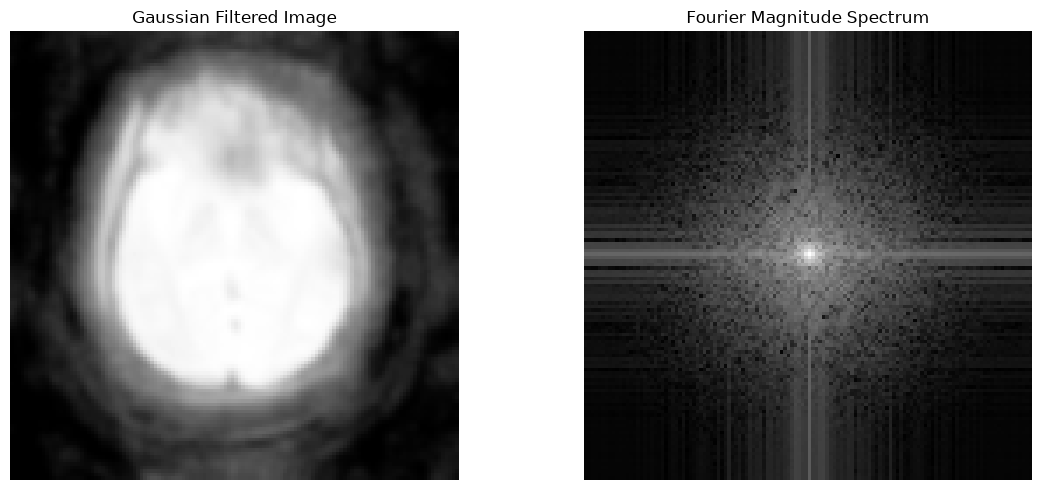

In [46]:
time_index = 0
z = fourier.shape[2] // 2

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    gaussian[:, :, z, time_index].T,
    cmap="gray",
    origin="lower"
)

plt.title("Gaussian Filtered Image")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    np.log1p(
        fourier[:, :, z, time_index]
    ).T,
    cmap="gray",
    origin="lower"
)

plt.title("Fourier Magnitude Spectrum")
plt.axis("off")

plt.tight_layout()
plt.show()

Low-Pass Filtering

In [47]:
import nibabel as nib
import numpy as np
from pathlib import Path

In [49]:
PROCESSED_DIR = Path(
    r"C:\Users\mmadh\dataset\processed_member1\processed_member1"
)

GAUSSIAN_DIR = PROCESSED_DIR / "gaussian"

LOWPASS_DIR = PROCESSED_DIR / "lowpass"
LOWPASS_DIR.mkdir(parents=True, exist_ok=True)

gaussian_files = sorted(
    GAUSSIAN_DIR.glob("*_gaussian.nii.gz")
)

print("Gaussian files:", len(gaussian_files))

Gaussian files: 40


In [50]:
cutoff = 0.15

for file in gaussian_files:

    subject = file.name.split("_gaussian")[0]

    print(f"Processing {subject}...")

    img = nib.load(file)
    data = img.get_fdata(dtype=np.float32)

    nx, ny, nz = data.shape[:3]

    # Frequency coordinates
    fx = np.fft.fftfreq(nx)
    fy = np.fft.fftfreq(ny)
    fz = np.fft.fftfreq(nz)

    FX, FY, FZ = np.meshgrid(
        fx,
        fy,
        fz,
        indexing="ij"
    )

    # Distance from zero frequency
    frequency_radius = np.sqrt(
        FX**2 +
        FY**2 +
        FZ**2
    )

    # Low-pass mask
    low_pass_mask = (
        frequency_radius <= cutoff
    )

    lowpass_data = np.zeros_like(
        data,
        dtype=np.float32
    )

    # Apply filter to every time frame
    for t in range(data.shape[3]):

        fft_volume = np.fft.fftn(
            data[:, :, :, t]
        )

        filtered_fft = (
            fft_volume *
            low_pass_mask
        )

        filtered_volume = np.fft.ifftn(
            filtered_fft
        )

        lowpass_data[:, :, :, t] = np.real(
            filtered_volume
        )

    # Save result
    output_file = (
        LOWPASS_DIR /
        f"{subject}_lowpass.nii.gz"
    )

    nib.save(
        nib.Nifti1Image(
            lowpass_data,
            img.affine,
            img.header
        ),
        output_file
    )

    del data
    del lowpass_data

    print(f"{subject} completed.")

Processing sub-01...
sub-01 completed.
Processing sub-02...
sub-02 completed.
Processing sub-03...
sub-03 completed.
Processing sub-04...
sub-04 completed.
Processing sub-05...
sub-05 completed.
Processing sub-06...
sub-06 completed.
Processing sub-07...
sub-07 completed.
Processing sub-08...
sub-08 completed.
Processing sub-09...
sub-09 completed.
Processing sub-10...
sub-10 completed.
Processing sub-11...
sub-11 completed.
Processing sub-12...
sub-12 completed.
Processing sub-13...
sub-13 completed.
Processing sub-14...
sub-14 completed.
Processing sub-15...
sub-15 completed.
Processing sub-16...
sub-16 completed.
Processing sub-17...
sub-17 completed.
Processing sub-18...
sub-18 completed.
Processing sub-19...
sub-19 completed.
Processing sub-20...
sub-20 completed.
Processing sub-21...
sub-21 completed.
Processing sub-22...
sub-22 completed.
Processing sub-23...
sub-23 completed.
Processing sub-24...
sub-24 completed.
Processing sub-25...
sub-25 completed.
Processing sub-26...
sub-

OSError: [Errno 28] No space left on device

In [54]:
lowpass_files = list(
    LOWPASS_DIR.glob("*.nii.gz")
)

print("Low-pass files created:", len(lowpass_files))

Low-pass files created: 32


In [55]:
LOWPASS_DIR = PROCESSED_DIR / "lowpass"

lowpass_file = (
    LOWPASS_DIR /
    f"{subject}_lowpass.nii.gz"
)

lowpass = nib.load(lowpass_file).get_fdata()

print("Low-pass shape:", lowpass.shape)

EOFError: Compressed file ended before the end-of-stream marker was reached

comparision bw three filtering

NameError: name 'lowpass' is not defined

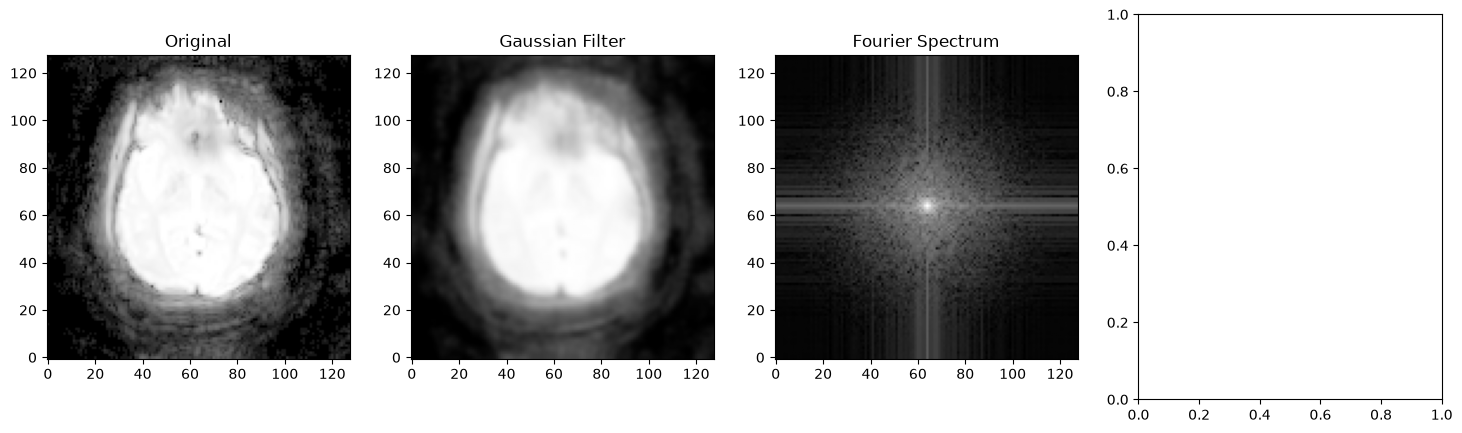

In [ ]:
time_index = 0
z = original.shape[2] // 2

fig, axes = plt.subplots(
    1, 4,
    figsize=(18, 5)
)

axes[0].imshow(
    original[:, :, z, time_index].T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title("Original")

axes[1].imshow(
    gaussian[:, :, z, time_index].T,
    cmap="gray",
    origin="lower"
)
axes[1].set_title("Gaussian Filter")

axes[2].imshow(
    np.log1p(
        fourier[:, :, z, time_index]
    ).T,
    cmap="gray",
    origin="lower"
)
axes[2].set_title("Fourier Spectrum")

axes[3].imshow(
    lowpass[:, :, z, time_index].T,
    cmap="gray",
    origin="lower"
)
axes[3].set_title("Low-Pass Filter")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()